### Deep Agents overview
Build agents that can plan, use subagents, and leverage file systems for complex tasks

deepagents is a standalone library for building agents that can tackle complex, multi-step tasks. Built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus, deep agents come with planning capabilities, file systems for context management, and the ability to spawn subagents.

### When to use deep agents
Use deep agents when you need agents that can:

1) Handle complex, multi-step tasks that require planning and decomposition
2) Manage large amounts of context through file system tools
3) Delegate work to specialized subagents for context isolation
4) Persist memory across conversations and threads

In [1]:
import os
from dotenv import load_dotenv
from langchain_openai import ChatOpenAI

load_dotenv()

llm = ChatOpenAI(
    model="prism-ml/ternary-bonsai-2-27b",
    api_key=os.getenv("OPENROUTER_API_KEY"),
    base_url="https://openrouter.ai/api/v1",
    max_tokens=1000,
)
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [2]:
from typing import Literal

In [6]:
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str,max_results:int=5,
topic: Literal["general","sports","news","finance"]="general",
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)

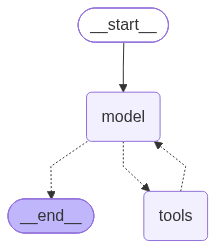

In [7]:
## Basic Agent
from langchain.agents import create_agent


simple_agent=create_agent(
    model=llm,
    tools=[web_search]
)
simple_agent

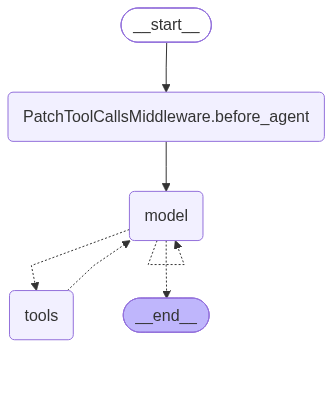

In [5]:
### Create a deep agent
## Prompt

## agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=llm,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [8]:
result = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='4d555f09-e48c-4b42-a56a-66d59719fdd6'),
  AIMessage(content='\n\n\n', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 146, 'prompt_tokens': 2670, 'total_tokens': 2816, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 58, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0.00027325, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0.00027325, 'upstream_inference_prompt_cost': 0.00020025, 'upstream_inference_completions_cost': 7.3e-05}}, 'model_provider': 'openai', 'model_name': 'prism-ml/ternary-bonsai-2-27b', 'system_fingerprint': None, 'id': 'gen-1791973493-pLZdBTQk1hi0pjLhYTlv', 'fini

In [9]:
result['files']

{}

## System Prompt
Deep agents come with a built-in system prompt inspired by Claude Code’s system prompt. The default system prompt contains detailed instructions for using the built-in planning tool, file system tools, and subagents. Each deep agent tailored to a use case should include a custom system prompt specific to that use case.

In [10]:
from deepagents import create_deep_agent

research_instructions = """\
You are an expert researcher. Your job is to conduct \
thorough research, and then write a polished report. \
"""

agent = create_deep_agent(
    model=llm,
    system_prompt=research_instructions,
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='9feffb3b-b980-452d-9e95-bcd18aaede93'),
  AIMessage(content='\n\n\n', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 529, 'prompt_tokens': 2604, 'total_tokens': 3133, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 476, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 2048, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0.000383, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0.000383, 'upstream_inference_prompt_cost': 0.0001185, 'upstream_inference_completions_cost': 0.0002645}}, 'model_provider': 'openai', 'model_name': 'prism-ml/ternary-bonsai-2-27b', 'system_fingerprint': None, 'id': 'gen-1791973684-WLpgrrbRodXRype6YIVg', 'fin

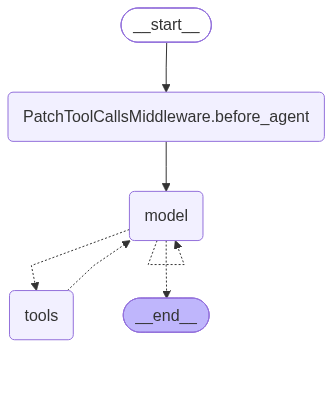

In [11]:
agent

In [12]:
### Tools
import os
from typing import Literal
from tavily import TavilyClient
from deepagents import create_deep_agent

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )

agent = create_deep_agent(
    model=llm,
    tools=[internet_search]
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent in Agentic AI?"}]})
result

{'messages': [HumanMessage(content='What is deepagent in Agentic AI?', additional_kwargs={}, response_metadata={}, id='28b7dc58-80a4-419d-a5de-104afd37c192'),
  AIMessage(content='\n\nI\'ll search to verify what "DeepAgent" refers to in the agentic AI space.\n\n\n', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 401, 'prompt_tokens': 2667, 'total_tokens': 3068, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': 0, 'reasoning_tokens': 293, 'rejected_prediction_tokens': None, 'text_tokens': None, 'image_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None, 'video_tokens': 0}, 'cost': 0.000400525, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 0.000400525, 'upstream_inference_prompt_cost': 0.000200025, 'upstream_inference_completions_cost': 0.0002005}}, 'model_provider': 'openai', 'model_name': 'prism-ml/ter

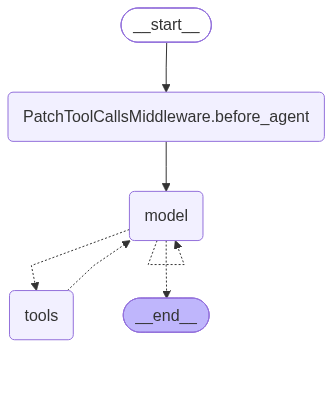

In [13]:
agent

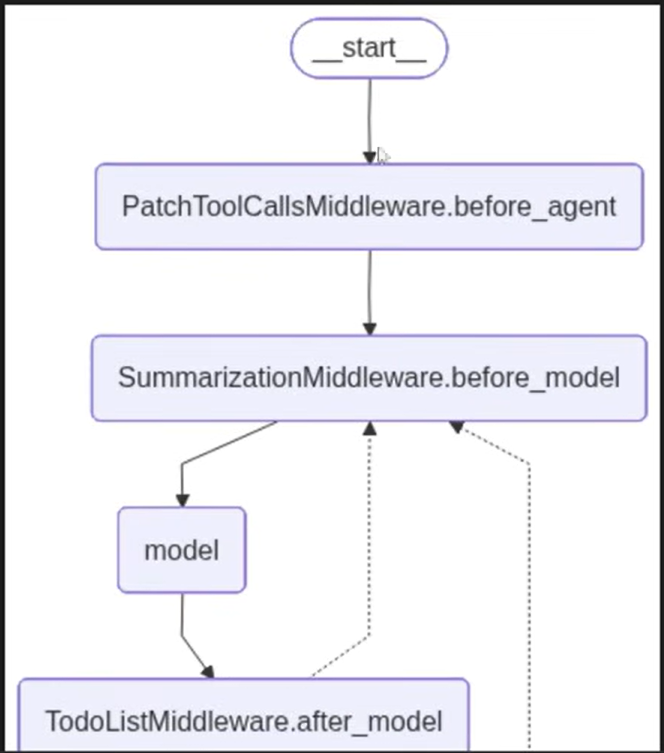

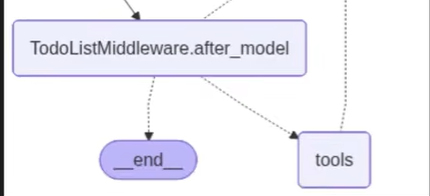